# NOAA versus CMIP6 equivalent-depth distributions: 2σ events

Daily 1990–2010 NOAA OLR is compared with 34 Historical and 25 AMIP simulations,
one member per simulation. All event counts and event-footprint energies below
use the completed **2σ longitudinal Hilbert-envelope catalogs**. The previous
1.5σ notebook and inputs are preserved in Git and the local data backup.

The questions remain distinct: which depths occur among fitted events, how
much OLR energy lies on their active pixels, and how observed Fourier power
is allocated by apparent depth? Figures appear only as notebook outputs.

## Inputs and choices

- Inputs are the audited tables in `data/event_threshold_comparison/distributions_sigma2/`. The audit requires 300 completed catalogs and 60 exact raw-input replays.
- Models use the existing daily OLR products on the NOAA 1-degree analysis grid, with one member per source/experiment.
- Active pixels satisfy `abs(Hilbert_lon(q)) > 2*std(q_reference)`. Sigma belongs to each dataset/wave and excludes 150 days at each record end. The same rectangular wave boxes, native calendars and raw constant-amplitude carrier fits are retained.
- **Screened** uses the existing `keep_for_histogram` flags; **relaxed** keeps successful fits with positive, dispersion-valid depths. The detector is identical for these two views.
- Event histograms normalize each source separately. All selected events, including those beyond a display limit, remain in the denominator. Log bins span 0.5–10,000 m; linear bins are 1 m wide.
- Event-footprint energy is filtered OLR squared on the new 2σ component pixels. Fitted energy is their local, in-sample sinusoid-explained sum of squares. Both divide by total preprocessed, projected OLR energy before wave filtering. The footprints and their energies are recomputed from raw input and matched to the saved 2σ event IDs and peaks.
- Observed spectral powers are threshold-independent and reuse the previous audited calculation. Only actual-data power is used; Gaussian-background comparisons are deferred.
- Model medians/interquartile bands describe between-simulation spread. They are not confidence intervals. NOAA supplies one record; some models occur in both experiments. Depths retain the assigned branch and zero-background-wind assumptions.

In [1]:
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from src.paths import DATA_DIR

DETECTION_SIGMA = 2.0
INPUT = DATA_DIR / "event_threshold_comparison/distributions_sigma2"
WAVES = ("Kelvin", "MRG", "n0EIG", "n1ERW", "n1WIG")
EXPERIMENTS = ("historical", "amip")
LINEAR_EDGES_M = np.arange(1.0, 201.0)
LOG_EDGES_M = np.geomspace(0.5, 10_000, 51)
COUNT_BINS = [f"count_{left:03d}m" for left in range(1, 200)]
LOG_BINS = [f"log_count_{index:02d}" for index in range(50)]
SUPPORT_BINS = [f"support_{left:03d}m" for left in range(1, 200)]
FITTED_BINS = [f"fitted_{left:03d}m" for left in range(1, 200)]
POWER_BINS = [f"power_{left:03d}m" for left in range(1, 200)]

audit = json.loads((INPUT / "audit.json").read_text())
assert audit["status"] == "complete" and audit["detection_sigma"] == DETECTION_SIGMA
assert audit["catalogs"] == 300 and audit["source_records"] == 60

def read_table(name):
    return pd.read_csv(INPUT / name)

model_counts = read_table("all_model_event_counts.csv.gz")
model_energy = read_table("all_model_event_energy.csv.gz")
model_spectral = read_table("all_model_spectral_power.csv.gz")
noaa_counts = read_table("noaa_event_counts.csv.gz")
noaa_energy = read_table("noaa_event_energy.csv.gz")
noaa_spectral = read_table("noaa_spectral_power.csv.gz")
for label, frame, expected in (
    ("model counts", model_counts, 590), ("model energy", model_energy, 590),
    ("NOAA counts", noaa_counts, 10), ("NOAA energy", noaa_energy, 10),
):
    assert len(frame) == expected and frame.detection_sigma.eq(DETECTION_SIGMA).all(), label
    assert set(frame.wave_type) == set(WAVES) and frame.selected_events.gt(0).all(), label
for frame, expected in ((model_spectral, 295), (noaa_spectral, 5)):
    assert len(frame) == expected and frame.source.eq("observed").all()
assert set(COUNT_BINS + LOG_BINS).issubset(model_counts)
assert set(SUPPORT_BINS + FITTED_BINS).issubset(model_energy)
assert set(POWER_BINS).issubset(model_spectral)
print("Loaded 2σ event diagnostics for NOAA, 34 Historical and 25 AMIP simulations.")


Loaded 2σ event diagnostics for NOAA, 34 Historical and 25 AMIP simulations.


## Integrated 12–50 m diagnostics

Each row describes one source. Event-share percentages divide by all selected
events. Event-energy percentages divide by total projected OLR energy; spectral
percentages divide by total projected spectral power. The 12–50 m interval is
a descriptive summary, not a detection restriction or a significance test.

In [2]:
KEY = ["model", "experiment", "member", "wave_type"]
SELECTION_KEY = KEY + ["selection"]

def integrated_metrics(counts, energy, spectral):
    count = counts[SELECTION_KEY + ["record_days", "selected_events"]].copy()
    count["event_share_12_to_50_pct"] = (
        100 * counts[[f"count_{left:03d}m" for left in range(12, 50)]].sum(axis=1)
        / counts.selected_events
    )
    count["events_per_1000_days"] = 1000 * counts.selected_events / counts.record_days
    event = energy[SELECTION_KEY].copy()
    for metric in ("support", "fitted"):
        bins = [f"{metric}_{left:03d}m" for left in range(12, 50)]
        event[f"{metric}_12_to_50_pct"] = 100 * energy[bins].sum(axis=1) / energy.denominator_energy
        event[f"{metric}_all_depths_pct"] = 100 * energy[f"selected_{metric}_energy"] / energy.denominator_energy
    spec = spectral[KEY].copy()
    spec["spectral_12_to_50_pct"] = 100 * spectral.twelve_to_50_m_power / spectral.denominator_power
    return (count.merge(event, on=SELECTION_KEY, validate="one_to_one")
            .merge(spec, on=KEY, validate="many_to_one"))

metrics = pd.concat((integrated_metrics(model_counts, model_energy, model_spectral),
                     integrated_metrics(noaa_counts, noaa_energy, noaa_spectral)), ignore_index=True)
assert len(metrics) == 600 and not metrics.duplicated(SELECTION_KEY).any()
primary = metrics.loc[metrics.selection.eq("screened")].copy()
METRICS = ["event_share_12_to_50_pct", "support_12_to_50_pct", "fitted_12_to_50_pct", "spectral_12_to_50_pct"]
display(primary.loc[primary.model.eq("NOAA_OLR"), ["wave_type", "selected_events", *METRICS]].round(3))
display(primary.loc[primary.model.ne("NOAA_OLR")].groupby(["experiment", "wave_type"])[METRICS].median().round(3))


,wave_type,selected_events,event_share_12_to_50_pct,support_12_to_50_pct,fitted_12_to_50_pct,spectral_12_to_50_pct
590,Kelvin,530,75.472,2.172,1.660,4.258
592,MRG,475,45.895,0.474,0.383,0.960
594,n0EIG,901,21.976,0.253,0.200,0.971
596,n1ERW,117,83.761,2.292,1.708,4.264
598,n1WIG,1300,8.923,0.052,0.041,0.294


event_share_12_to_50_pct  support_12_to_50_pct  \
experiment wave_type                                                   
amip       Kelvin                       46.652                 0.888   
           MRG                          36.574                 0.330   
           n0EIG                         2.851                 0.012   
           n1ERW                        67.273                 1.624   
           n1WIG                         2.048                 0.003   
historical Kelvin                       45.899                 0.866   
           MRG                          37.123                 0.343   
           n0EIG                         3.131                 0.015   
           n1ERW                        72.524                 1.641   
           n1WIG                         1.553                 0.003   

                      fitted_12_to_50_pct  spectral_12_to_50_pct  
experiment wave_type                                              
amip       Kelvin                   0.662                  2.283  
           MRG                      0.274                  0.692  
           n0EIG                    0.010                  0.294  
           n1ERW                    1.160                  4.664  
           n1WIG                    0.002                  0.110  
historical Kelvin                   0.684                  2.485  
           MRG                      0.294                  0.696  
           n0EIG                    0.011                  0.345  
           n1ERW                    1.240                  4.547  
           n1WIG                    0.002                  0.123

The next table keeps the **individual** simulations visible. `support_12_to_50_pct` is the event-footprint energy share; sort or filter `primary` to inspect the other metrics or the relaxed selection. Historical and AMIP should not be pooled as if their records were independent members of one experiment.


In [3]:
model_table = primary.loc[primary.model.ne("NOAA_OLR")].pivot(
    index=["model", "experiment", "member"], columns="wave_type",
    values="support_12_to_50_pct")
display(model_table.reindex(columns=WAVES).round(3))


wave_type                            Kelvin    MRG  n0EIG  n1ERW  n1WIG
model           experiment member                                      
ACCESS-CM2      amip       r1i1p1f1   0.905  0.319  0.015  1.466  0.004
                historical r1i1p1f1   1.332  0.368  0.009  1.276  0.008
ACCESS-ESM1-5   amip       r1i1p1f1   0.623  0.306  0.003  1.831  0.004
                historical r1i1p1f1   0.646  0.359  0.003  1.864  0.001
AWI-ESM-1-1-LR  historical r1i1p1f1   0.509  0.304  0.005  2.330  0.001
AWI-ESM-1-REcoM historical r1i1p1f1   0.592  0.275  0.005  2.116  0.000
BCC-CSM2-MR     amip       r1i1p1f1   1.777  0.428  0.070  1.305  0.072
                historical r2i1p1f1   2.549  0.429  0.090  1.802  0.096
BCC-ESM1        historical r1i1p1f1   1.803  0.357  0.027  1.219  0.014
CESM2           amip       r1i1p1f1   1.182  0.724  0.060  1.757  0.007
                historical r1i1p1f1   1.245  0.508  0.043  1.512  0.006
CESM2-FV2       amip       r1i1p1f1   0.888  0.787  0.120  1.846  0.010
                historical r1i1p1f1   1.094  0.660  0.104  1.123  0.012
CESM2-WACCM     amip       r1i1p1f1   1.348  0.674  0.058  1.629  0.009
                historical r1i1p1f1   1.769  0.546  0.067  1.509  0.007
CESM2-WACCM-FV2 amip       r1i1p1f1   1.077  0.901  0.089  1.656  0.019
                historical r1i1p1f1   1.348  0.597  0.095  1.196  0.019
CMCC-CM2-SR5    historical r1i1p1f1   1.947  1.069  0.030  1.636  0.002
CNRM-CM6-1      amip       r1i1p1f2   0.400  0.260  0.012  1.296  0.002
                historical r1i1p1f2   0.276  0.301  0.020  1.535  0.003
CNRM-CM6-1-HR   amip       r1i1p1f2   0.653  0.468  0.015  1.498  0.001
                historical r1i1p1f2   0.589  0.373  0.025  1.553  0.001
CNRM-ESM2-1     amip       r1i1p1f2   0.329  0.268  0.012  1.596  0.002
                historical r1i1p1f2   0.339  0.309  0.022  1.583  0.002
CanESM5         amip       r1i1p1f1   0.703  0.191  0.002  1.067  0.003
                historical r1i1p1f1   0.785  0.250  0.007  1.718  0.003
FGOALS-g3       historical r1i1p1f1   0.844  0.199  0.016  1.646  0.004
GFDL-CM4        amip       r1i1p1f1   0.473  0.369  0.006  1.451  0.000
                historical r1i1p1f1   0.655  0.328  0.008  1.479  0.001
GISS-E2-1-G     amip       r1i1p1f1   0.607  0.331  0.003  1.250  0.000
                historical r1i1p1f1   0.759  0.323  0.005  1.488  0.001
HadGEM3-GC31-LL amip       r1i1p1f3   0.956  0.408  0.016  1.624  0.003
                historical r1i1p1f3   1.249  0.389  0.018  1.485  0.004
HadGEM3-GC31-MM amip       r2i1p1f3   0.981  0.370  0.020  1.653  0.005
                historical r1i1p1f3   1.720  0.385  0.023  1.928  0.003
ICON-ESM-LR     amip       r1i1p1f1   0.500  0.330  0.006  1.369  0.001
                historical r1i1p1f1   0.358  0.353  0.003  1.812  0.000
INM-CM4-8       amip       r1i1p1f1   0.336  0.177  0.001  1.379  0.000
                historical r1i1p1f1   0.330  0.303  0.000  1.699  0.000
INM-CM5-0       amip       r1i1p1f1   0.328  0.167  0.001  1.879  0.000
                historical r1i1p1f1   0.378  0.260  0.001  2.006  0.000
IPSL-CM6A-LR    amip       r1i1p1f1   0.685  0.181  0.010  1.998  0.003
                historical r1i1p1f1   0.770  0.187  0.012  2.205  0.003
KACE-1-0-G      historical r1i1p1f1   1.261  0.332  0.017  1.433  0.003
MIROC6          amip       r1i1p1f1   1.163  0.415  0.013  1.705  0.003
                historical r1i1p1f1   1.659  0.332  0.010  1.349  0.002
MPI-ESM-1-2-HAM amip       r1i1p1f1   1.218  0.125  0.031  1.467  0.009
                historical r1i1p1f1   0.629  0.167  0.029  2.927  0.004
MPI-ESM1-2-HR   amip       r1i1p1f1   1.050  0.281  0.003  1.801  0.001
                historical r1i1p1f1   0.888  0.248  0.006  1.845  0.001
MPI-ESM1-2-LR   amip       r1i1p1f1   0.907  0.211  0.005  2.386  0.002
                historical r1i1p1f1   0.745  0.275  0.003  3.709  0.001
MRI-ESM2-0      amip       r1i1p1f1   0.804  0.316  0.005  1.441  0.001
                historical r1i1p1f1   0.

## Fitted event-depth distributions

Each standalone panel compares NOAA with Historical and AMIP **model medians** and interquartile ranges. A model contributes one normalized curve, regardless of its event count. These log-bin curves include the high-depth tails omitted from the 1–200 m energy panels. The primary fit-quality screen is shown; the `metrics` table also contains relaxed-selection results.


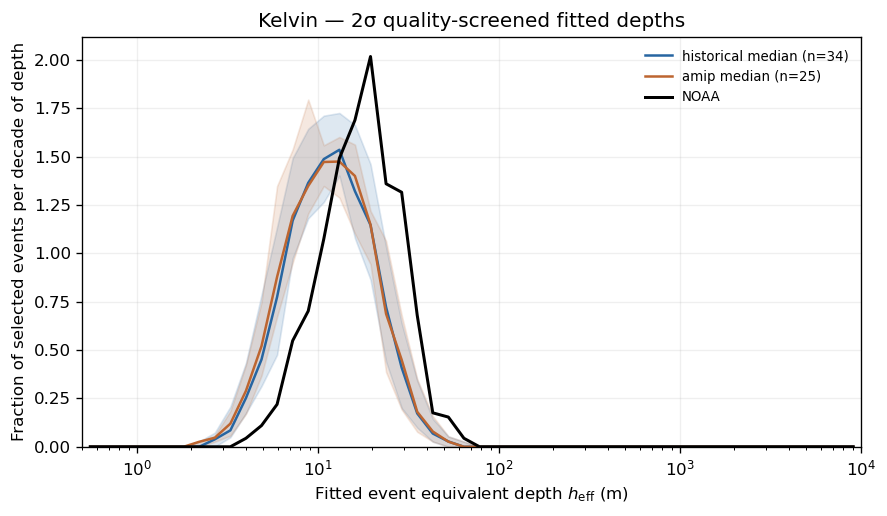

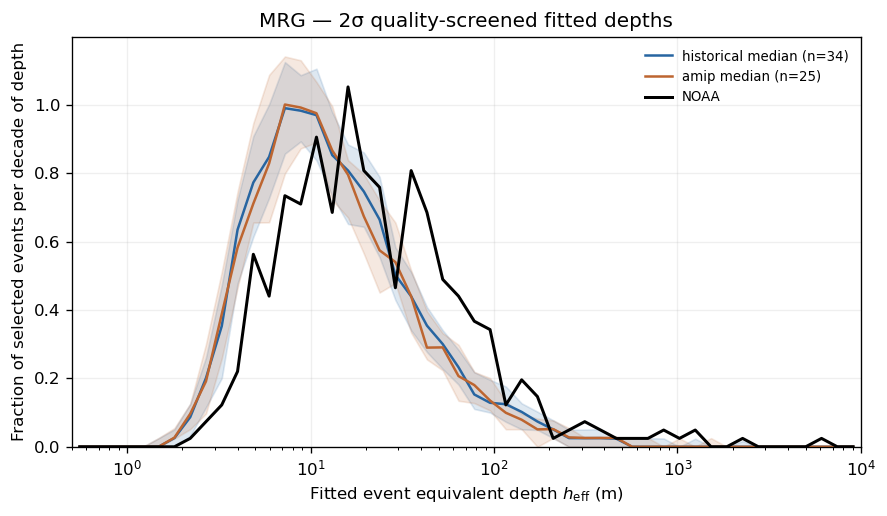

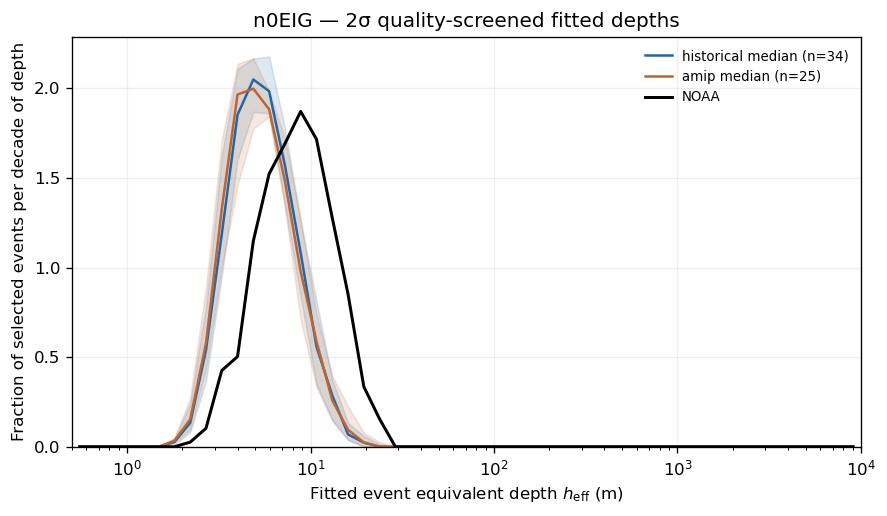

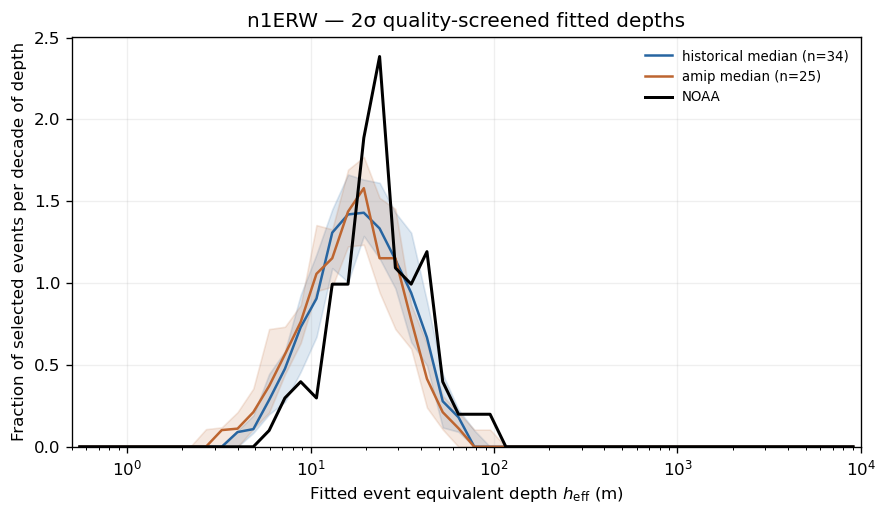

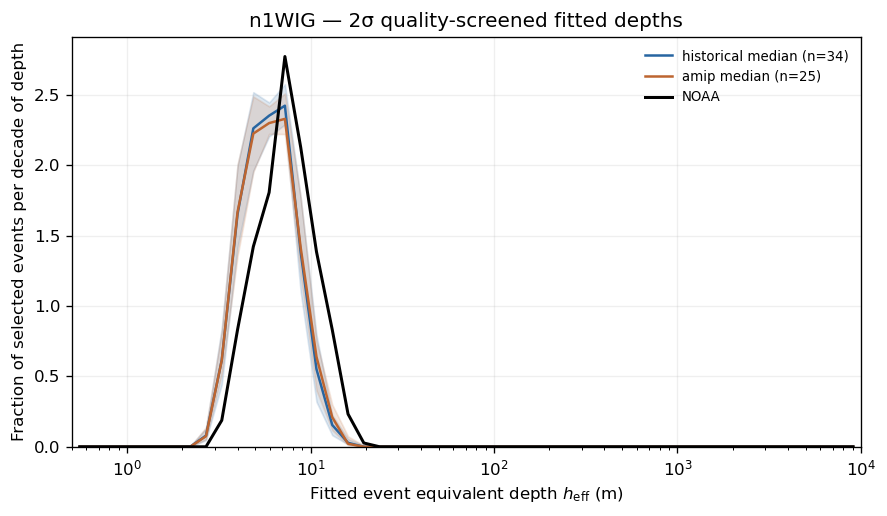

In [4]:
log_widths = np.diff(np.log10(LOG_EDGES_M))
for wave in WAVES:
    fig, ax = plt.subplots(figsize=(7.5, 4.4), dpi=120)
    for experiment, color in (("historical", "#2765a1"), ("amip", "#bd6530")):
        rows = model_counts.loc[(model_counts.wave_type == wave)
                                & (model_counts.selection == "screened")
                                & (model_counts.experiment == experiment)]
        density = rows[LOG_BINS].to_numpy() / rows.selected_events.to_numpy()[:, None] / log_widths
        low, median, high = np.quantile(density, [0.25, 0.5, 0.75], axis=0)
        centers = np.sqrt(LOG_EDGES_M[:-1] * LOG_EDGES_M[1:])
        ax.plot(centers, median, color=color, label=f"{experiment} median (n={len(rows)})")
        ax.fill_between(centers, low, high, color=color, alpha=0.15)
    row = noaa_counts.loc[(noaa_counts.wave_type == wave)
                          & (noaa_counts.selection == "screened")].iloc[0]
    noaa_density = row[LOG_BINS].to_numpy(dtype=float) / row.selected_events / log_widths
    ax.plot(centers, noaa_density, color="black", linewidth=1.8, label="NOAA")
    ax.set(xscale="log", xlim=(0.5, 10_000), ylim=(0, None),
           xlabel=r"Fitted event equivalent depth $h_{\mathrm{eff}}$ (m)",
           ylabel="Fraction of selected events per decade of depth",
           title=f"{wave} — 2σ quality-screened fitted depths")
    ax.grid(alpha=0.2)
    ax.legend(frameon=False, fontsize=8)
    fig.tight_layout()
    display(fig)
    plt.close(fig)


## Linear detail: fitted event depths from 1 to 100 m

Each panel uses 1 m bins (1–2, 2–3, …, 99–100 m). The y-axis is the **percentage of all selected events in that record** per bin; events outside 1–100 m remain in the denominator. Historical and AMIP lines are medians of individually normalized model records, with between-simulation interquartile bands. NOAA is one record. Both the standard fit-quality screen and the relaxed finite-depth selection are shown, so changes in the screen are visible without changing the event detector.

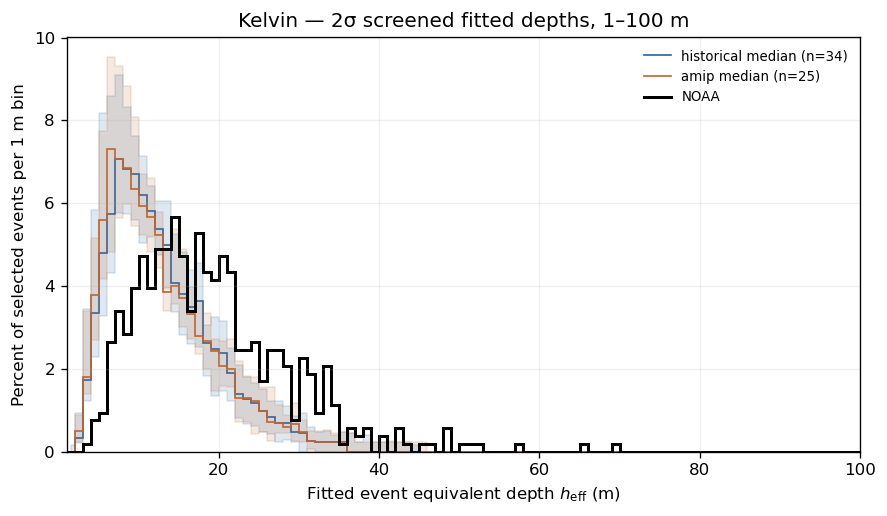

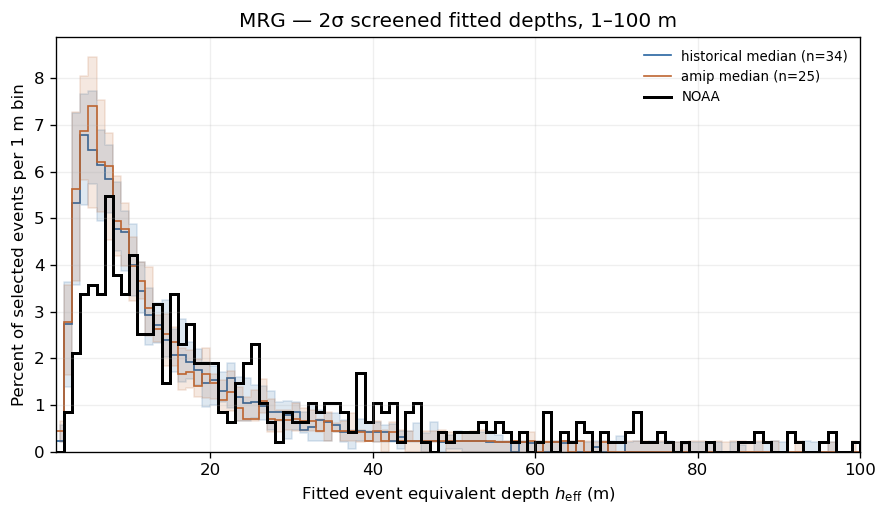

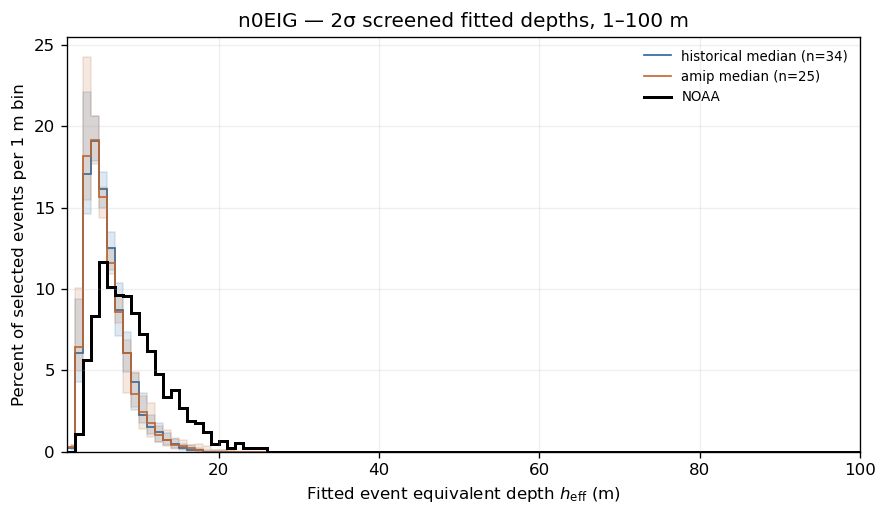

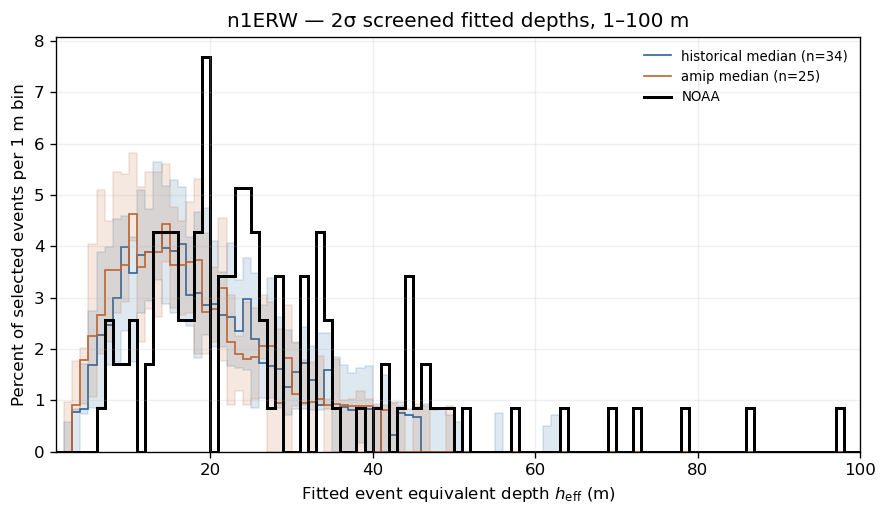

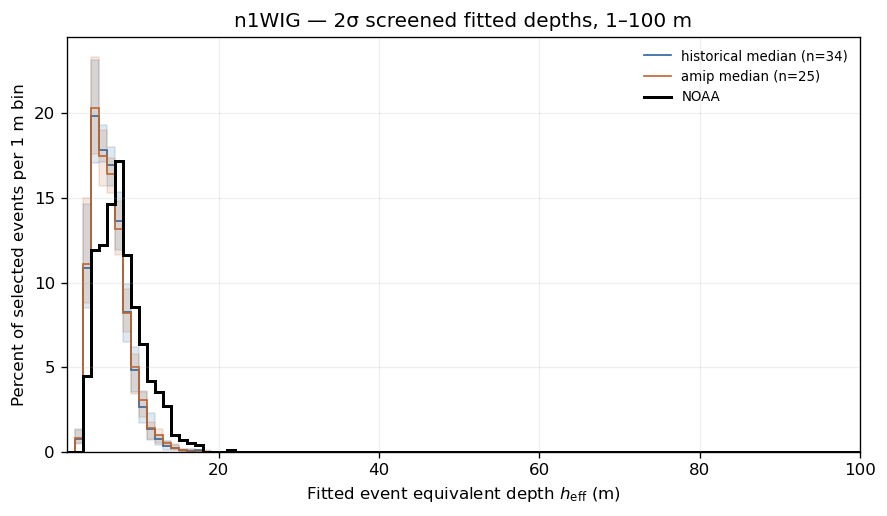

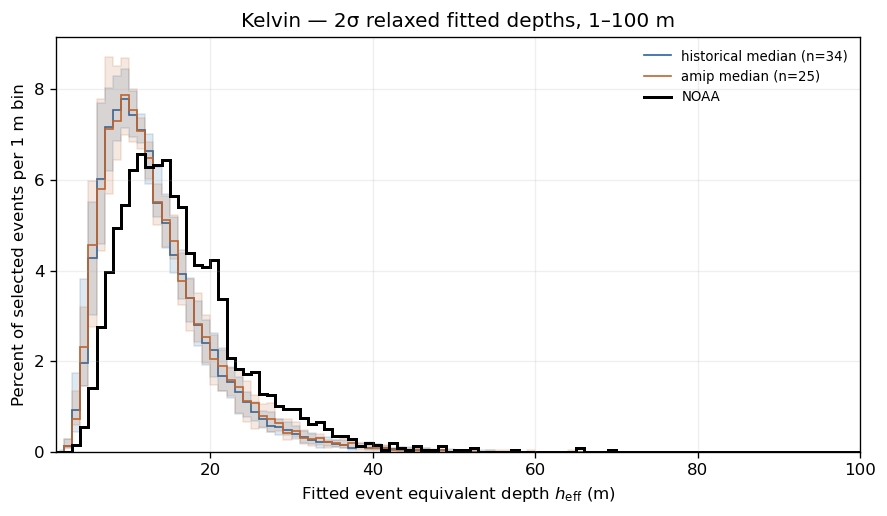

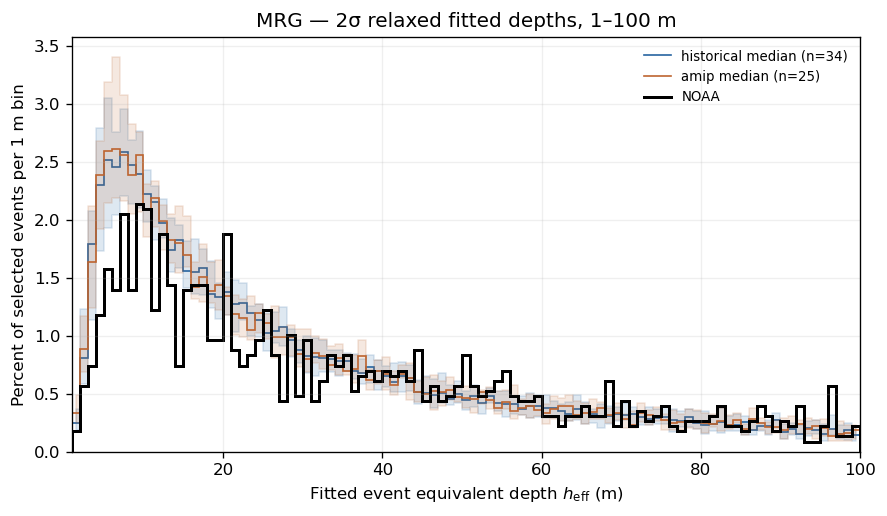

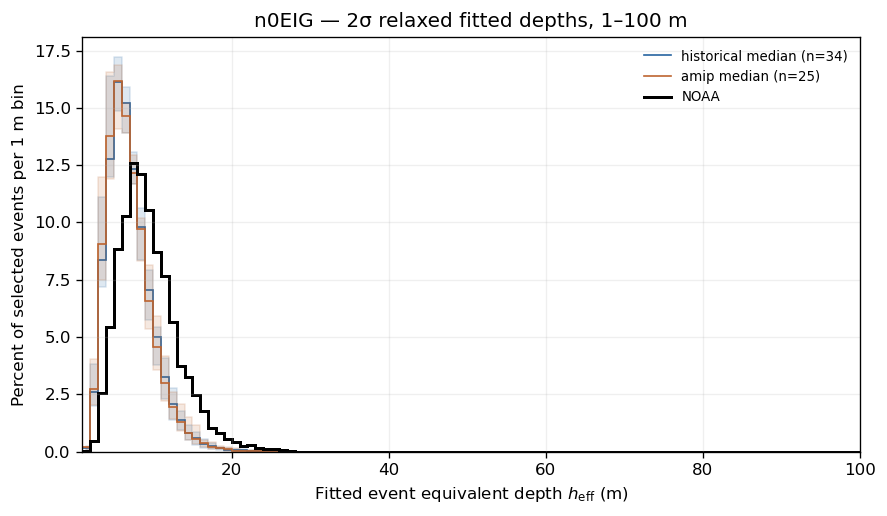

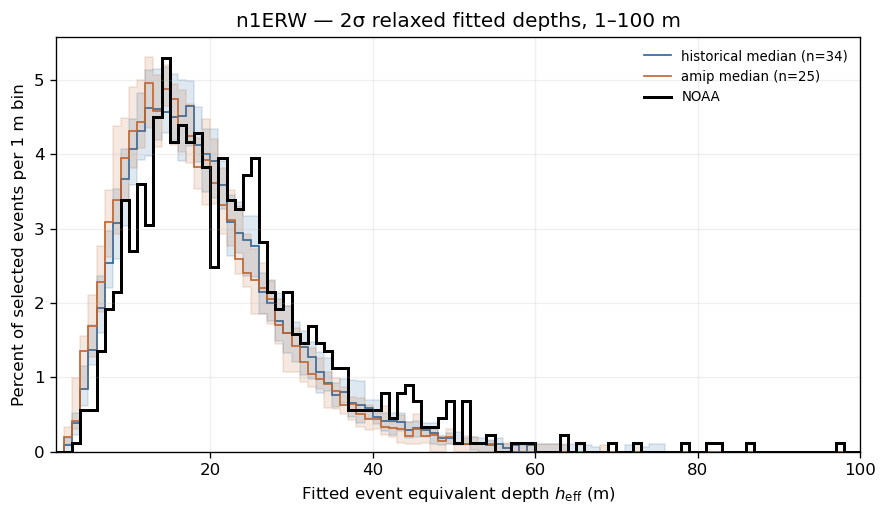

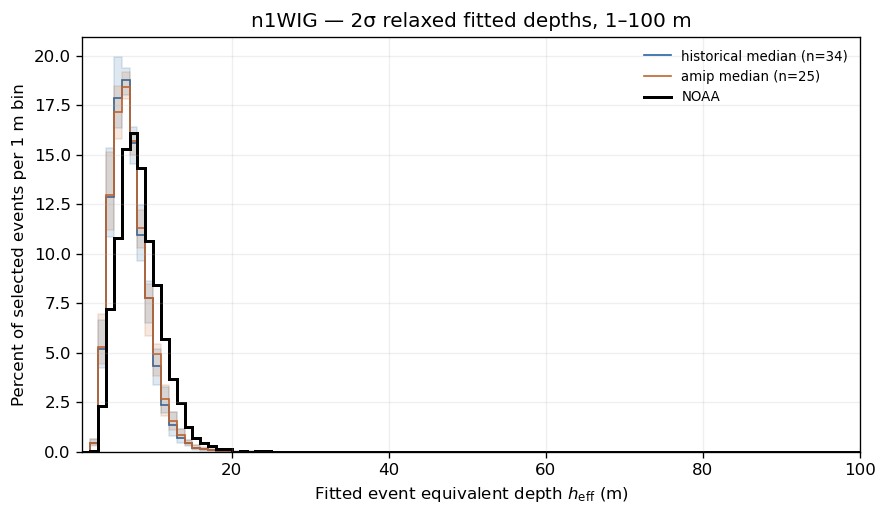

In [5]:
LINEAR_DETAIL_EDGES_M = np.arange(1.0, 101.0)
LINEAR_DETAIL_BINS = [f"count_{left:03d}m" for left in range(1, 100)]
LINEAR_DETAIL_CENTERS_M = (LINEAR_DETAIL_EDGES_M[:-1] + LINEAR_DETAIL_EDGES_M[1:]) / 2

for selection in ("screened", "relaxed"):
    for wave in WAVES:
        fig, ax = plt.subplots(figsize=(7.5, 4.4), dpi=120)
        for experiment, color in (("historical", "#2765a1"), ("amip", "#bd6530")):
            rows = model_counts.loc[(model_counts.wave_type == wave)
                                    & (model_counts.selection == selection)
                                    & (model_counts.experiment == experiment)]
            percent = (100 * rows[LINEAR_DETAIL_BINS].to_numpy()
                       / rows.selected_events.to_numpy()[:, None])
            low, median, high = np.quantile(percent, [0.25, 0.5, 0.75], axis=0)
            ax.stairs(median, LINEAR_DETAIL_EDGES_M, color=color,
                      label=f"{experiment} median (n={len(rows)})")
            ax.fill_between(LINEAR_DETAIL_CENTERS_M, low, high,
                            step="mid", color=color, alpha=0.15)
        row = noaa_counts.loc[(noaa_counts.wave_type == wave)
                              & (noaa_counts.selection == selection)].iloc[0]
        noaa_percent = (100 * row[LINEAR_DETAIL_BINS].to_numpy(dtype=float)
                        / row.selected_events)
        ax.stairs(noaa_percent, LINEAR_DETAIL_EDGES_M, color="black",
                  linewidth=1.8, label="NOAA")
        ax.set(xlim=(1, 100), ylim=(0, None),
               xlabel=r"Fitted event equivalent depth $h_{\mathrm{eff}}$ (m)",
               ylabel="Percent of selected events per 1 m bin",
               title=f"{wave} — 2σ {selection} fitted depths, 1–100 m")
        ax.grid(alpha=0.2)
        ax.legend(frameon=False, fontsize=8)
        fig.tight_layout()
        display(fig)
        plt.close(fig)


## Individual-model spread in fitted depths, 1–100 m

Each faint line is one available model/experiment record (one member per simulation). The bold Historical and AMIP curves are arithmetic means of the individually normalized model histograms; each simulation has equal weight. NOAA is black. The 1 m bins and percentage denominator match the linear median panels above: events outside 1–100 m remain in the denominator. Both screened and relaxed selections are shown. These lines display between-simulation spread, not uncertainty in the ensemble mean.


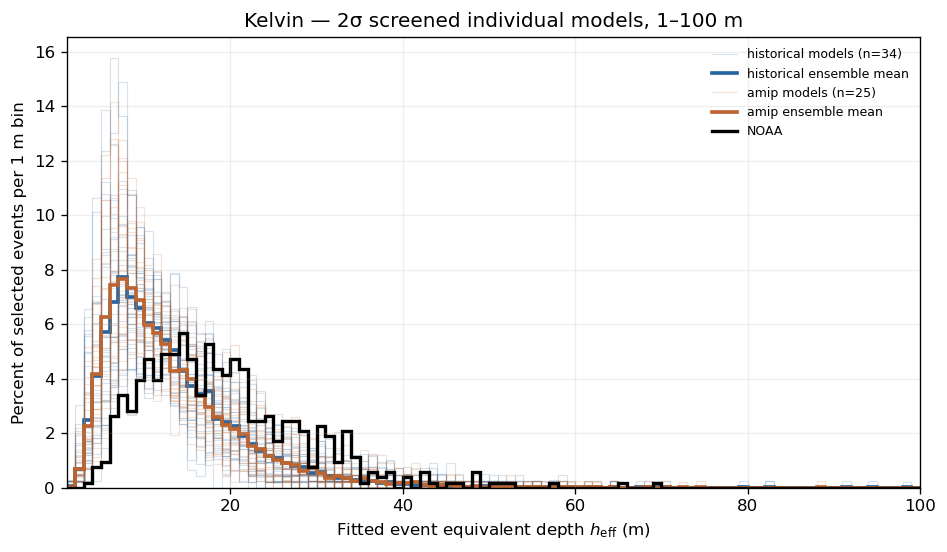

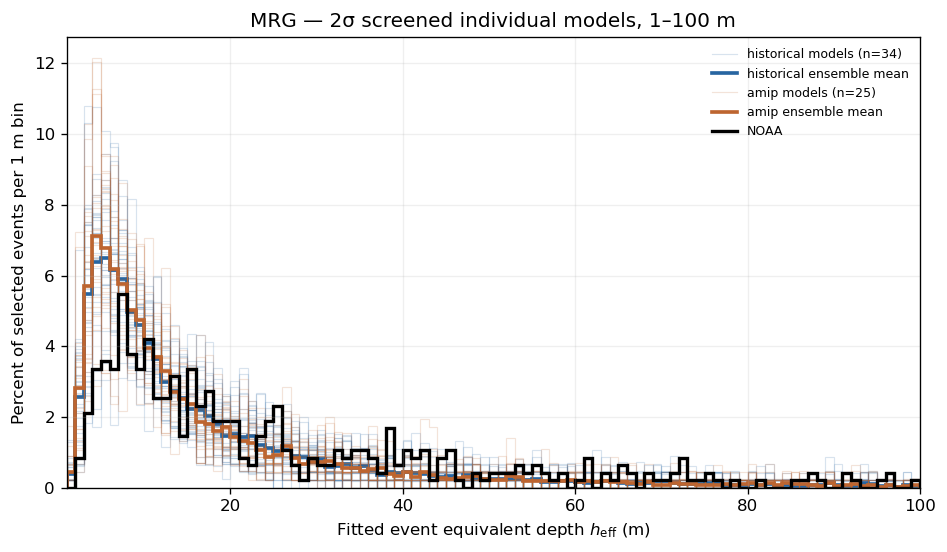

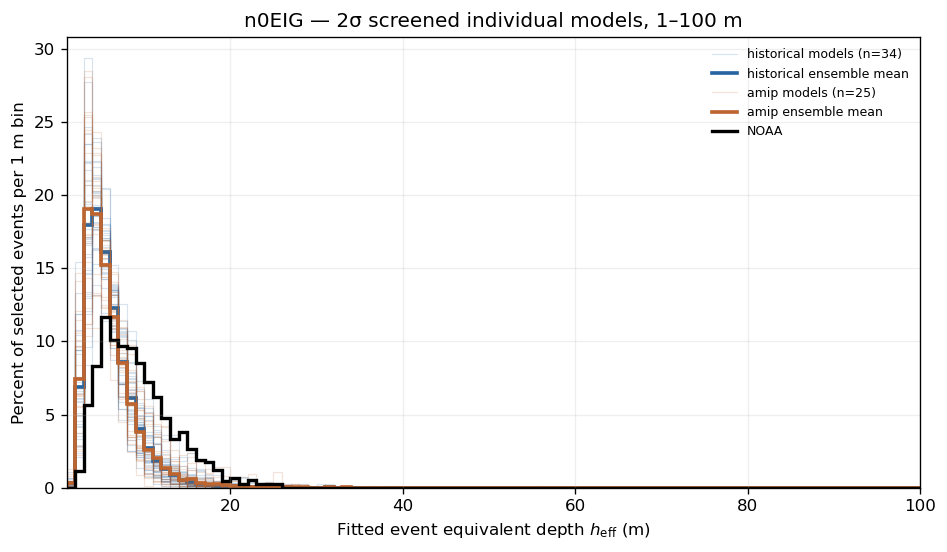

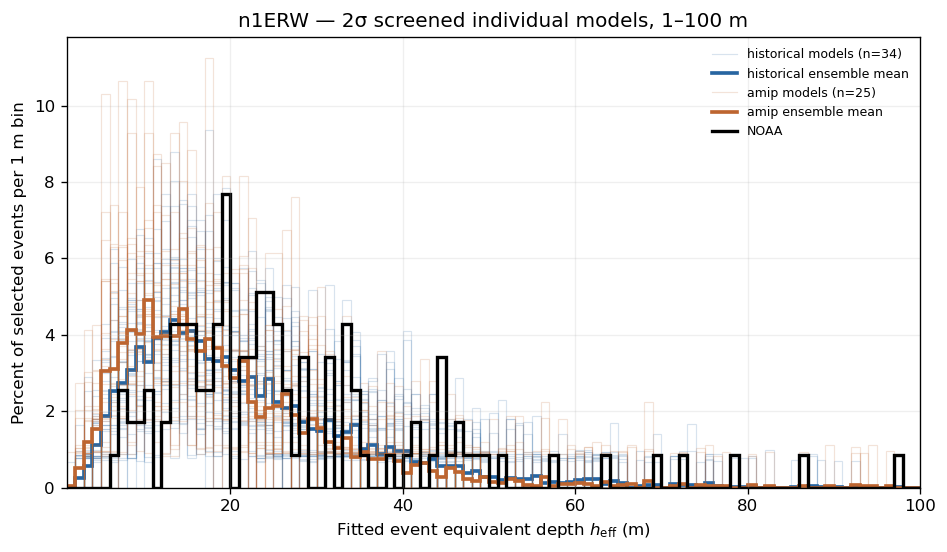

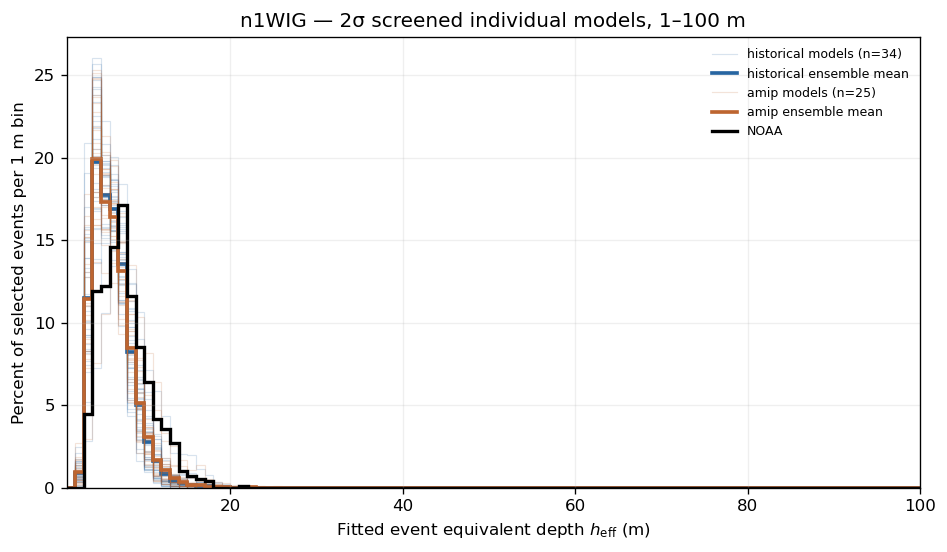

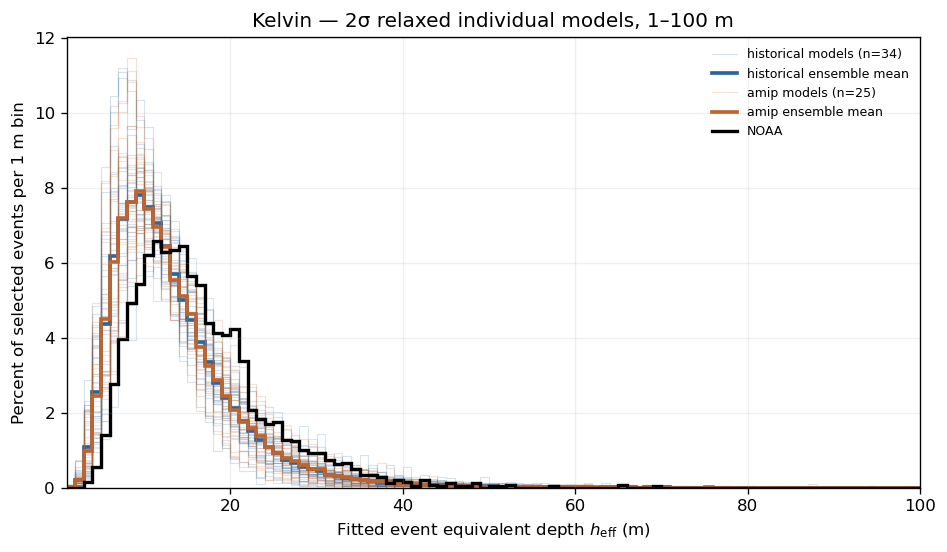

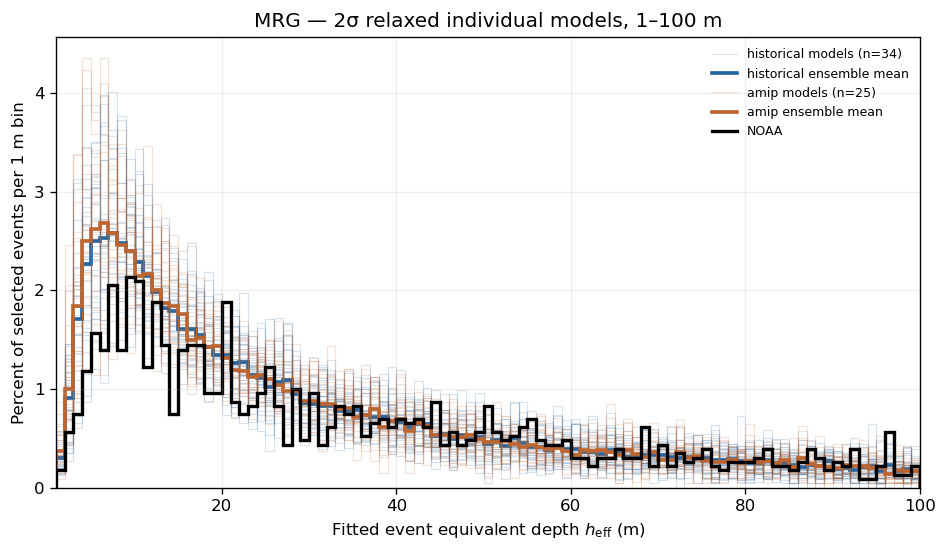

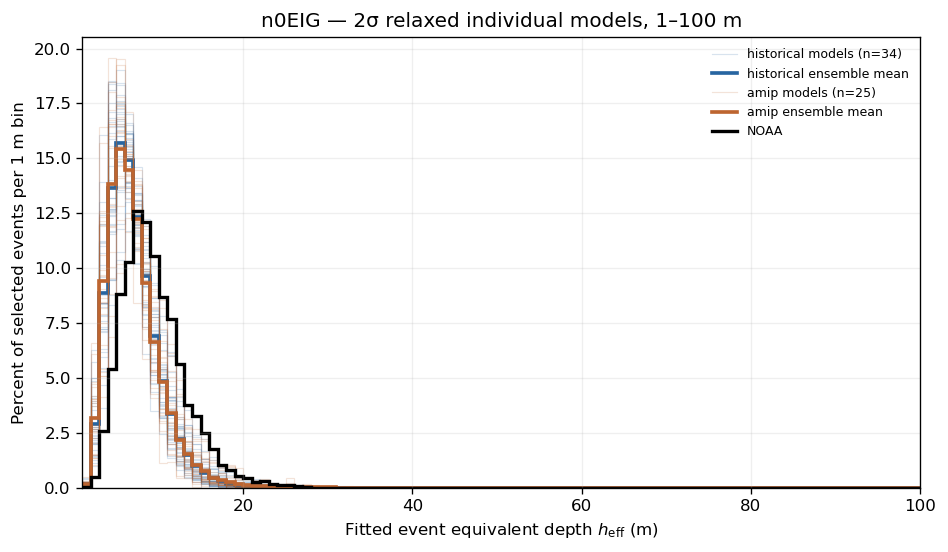

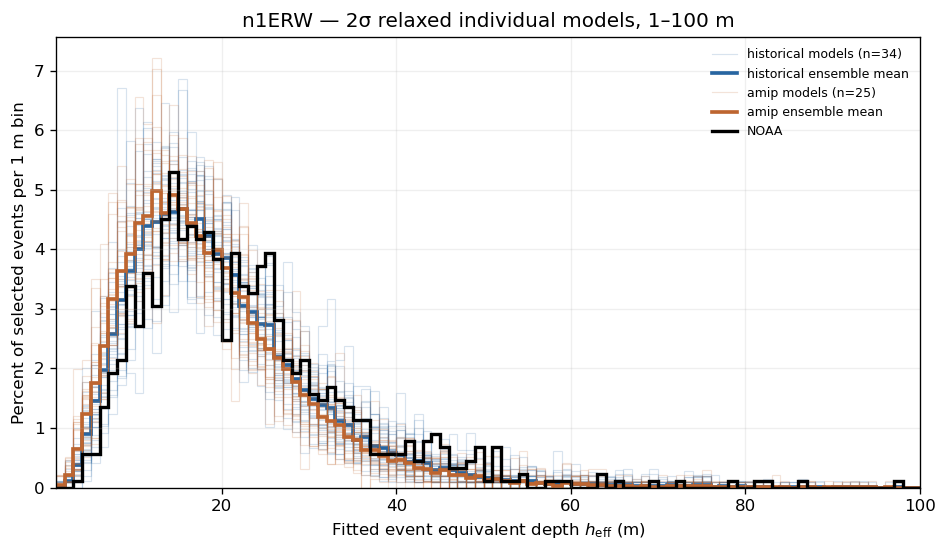

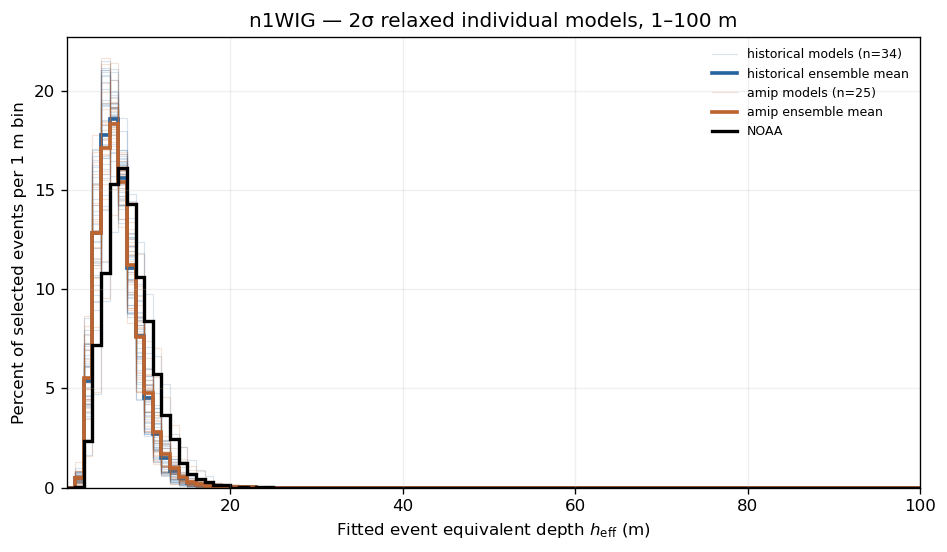

In [6]:
for selection in ("screened", "relaxed"):
    for wave in WAVES:
        fig, ax = plt.subplots(figsize=(8.0, 4.7), dpi=120)
        for experiment, color in (("historical", "#2765a1"), ("amip", "#bd6530")):
            rows = model_counts.loc[(model_counts.wave_type == wave)
                                    & (model_counts.selection == selection)
                                    & (model_counts.experiment == experiment)].sort_values(["model", "member"])
            percent = (100 * rows[LINEAR_DETAIL_BINS].to_numpy(dtype=float)
                       / rows.selected_events.to_numpy()[:, None])
            for index, values in enumerate(percent):
                ax.stairs(values, LINEAR_DETAIL_EDGES_M, color=color,
                          linewidth=0.7, alpha=0.18,
                          label=f"{experiment} models (n={len(rows)})" if index == 0 else "_nolegend_")
            ax.stairs(percent.mean(axis=0), LINEAR_DETAIL_EDGES_M, color=color,
                      linewidth=2.2, label=f"{experiment} ensemble mean")
        row = noaa_counts.loc[(noaa_counts.wave_type == wave)
                              & (noaa_counts.selection == selection)].iloc[0]
        noaa_percent = (100 * row[LINEAR_DETAIL_BINS].to_numpy(dtype=float)
                        / row.selected_events)
        ax.stairs(noaa_percent, LINEAR_DETAIL_EDGES_M, color="black",
                  linewidth=2.0, label="NOAA")
        ax.set(xlim=(1, 100), ylim=(0, None),
               xlabel=r"Fitted event equivalent depth $h_{\mathrm{eff}}$ (m)",
               ylabel="Percent of selected events per 1 m bin",
               title=f"{wave} — 2σ {selection} individual models, 1–100 m")
        ax.grid(alpha=0.2)
        ax.legend(frameon=False, fontsize=7.5)
        fig.tight_layout()
        display(fig)
        plt.close(fig)


## Event-footprint energy by fitted depth

The y-axis is percent of each record's **total projected OLR anomaly energy per 1 m bin**. It therefore retains differences in both event prevalence and event strength across records. The model bands show between-simulation spread, not uncertainty for an individual model or NOAA. The tabulated `fitted_12_to_50_pct` gives the corresponding sinusoid-explained diagnostic.


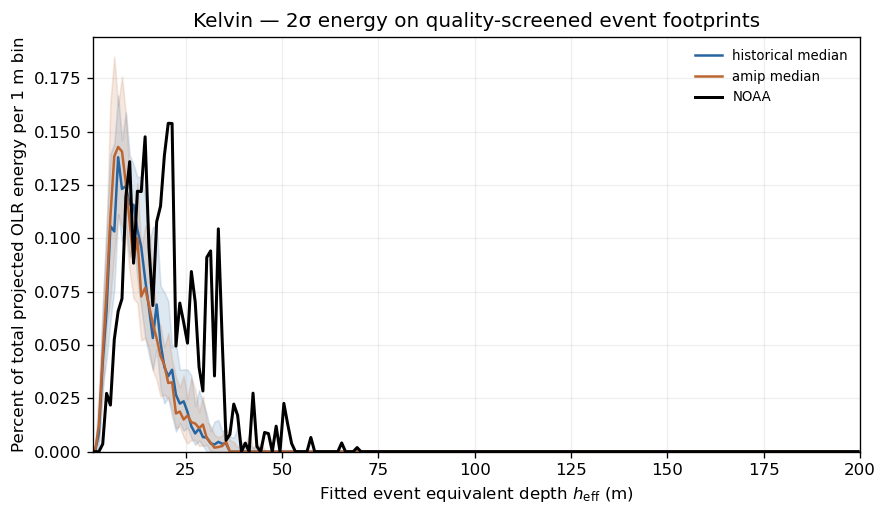

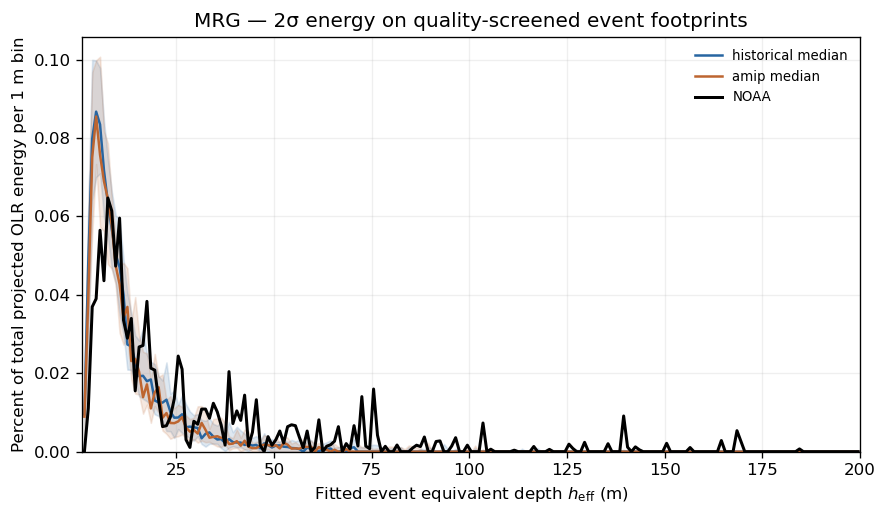

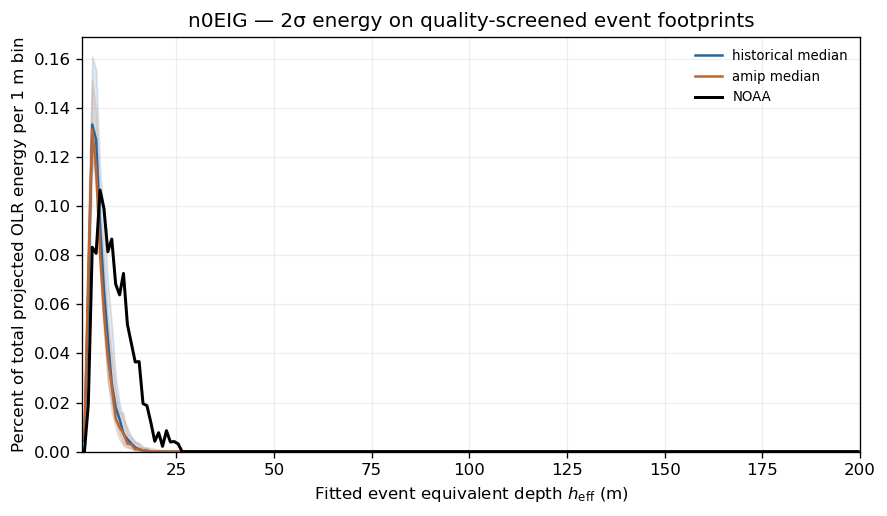

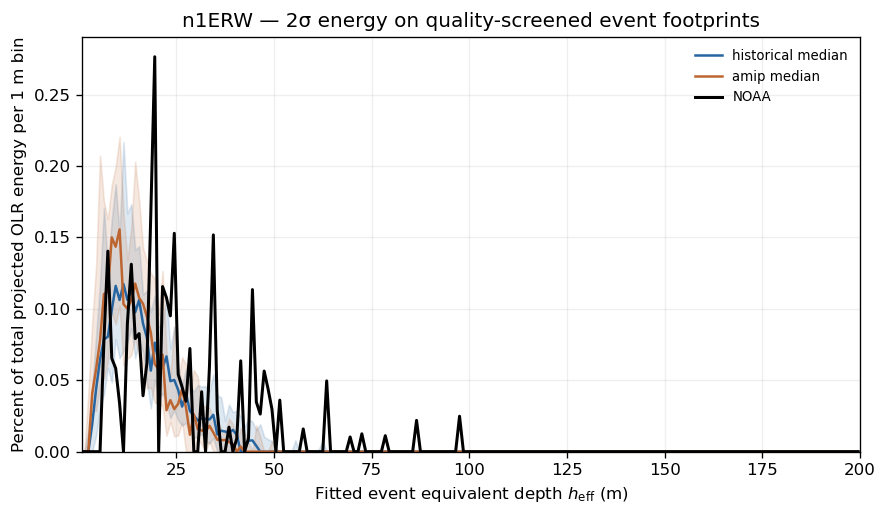

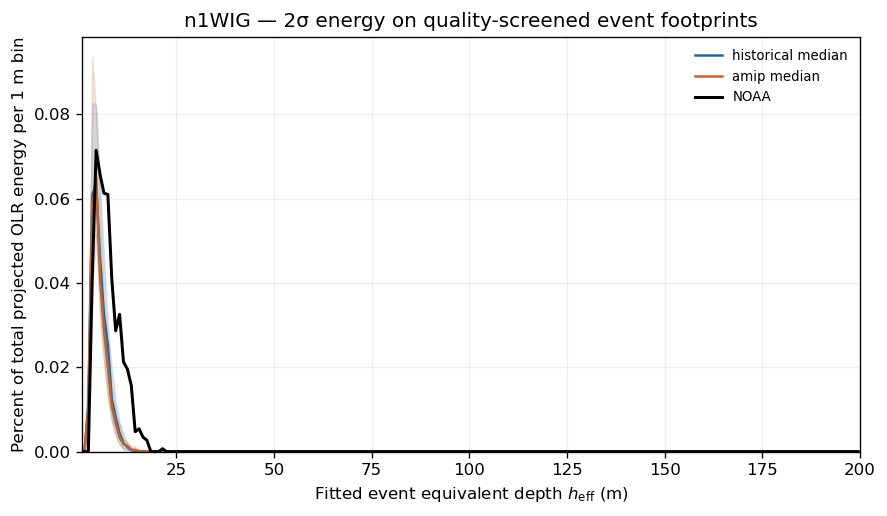

In [7]:
centers = (LINEAR_EDGES_M[:-1] + LINEAR_EDGES_M[1:]) / 2
for wave in WAVES:
    fig, ax = plt.subplots(figsize=(7.5, 4.4), dpi=120)
    for experiment, color in (("historical", "#2765a1"), ("amip", "#bd6530")):
        rows = model_energy.loc[(model_energy.wave_type == wave)
                                & (model_energy.selection == "screened")
                                & (model_energy.experiment == experiment)]
        fractions = 100 * rows[SUPPORT_BINS].to_numpy() / rows.denominator_energy.to_numpy()[:, None]
        low, median, high = np.quantile(fractions, [0.25, 0.5, 0.75], axis=0)
        ax.plot(centers, median, color=color, label=f"{experiment} median")
        ax.fill_between(centers, low, high, color=color, alpha=0.15)
    row = noaa_energy.loc[(noaa_energy.wave_type == wave)
                          & (noaa_energy.selection == "screened")].iloc[0]
    noaa_fraction = 100 * row[SUPPORT_BINS].to_numpy(dtype=float) / row.denominator_energy
    ax.plot(centers, noaa_fraction, color="black", linewidth=1.8, label="NOAA")
    ax.set(xlim=(1, 200), ylim=(0, None),
           xlabel=r"Fitted event equivalent depth $h_{\mathrm{eff}}$ (m)",
           ylabel="Percent of total projected OLR energy per 1 m bin",
           title=f"{wave} — 2σ energy on quality-screened event footprints")
    ax.grid(alpha=0.2)
    ax.legend(frameon=False, fontsize=8)
    fig.tight_layout()
    display(fig)
    plt.close(fig)


## Spectral power by apparent depth

This calculation is independent of the event detector and fit-quality screen.
It reuses observed Fourier power from the same record and wave boxes; no
Gaussian spectrum or observed/background ratio enters this remake. These
apparent depths belong to Fourier cells rather than fitted event components.

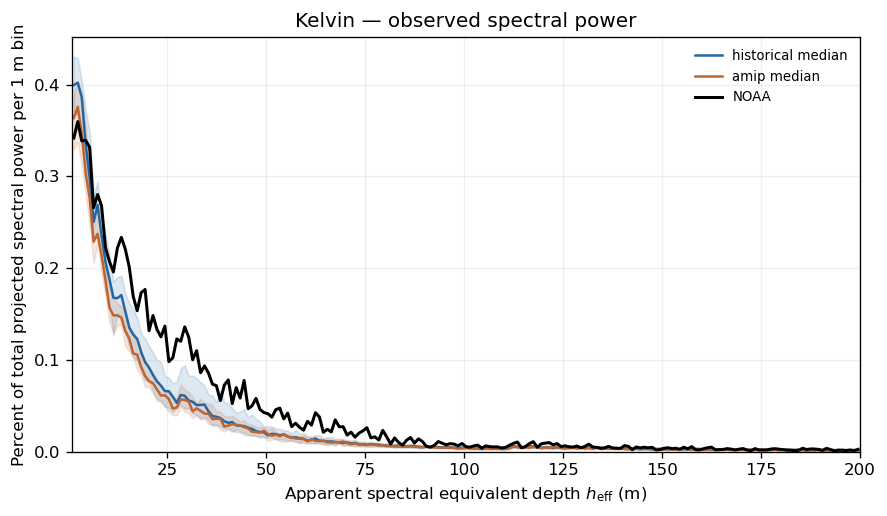

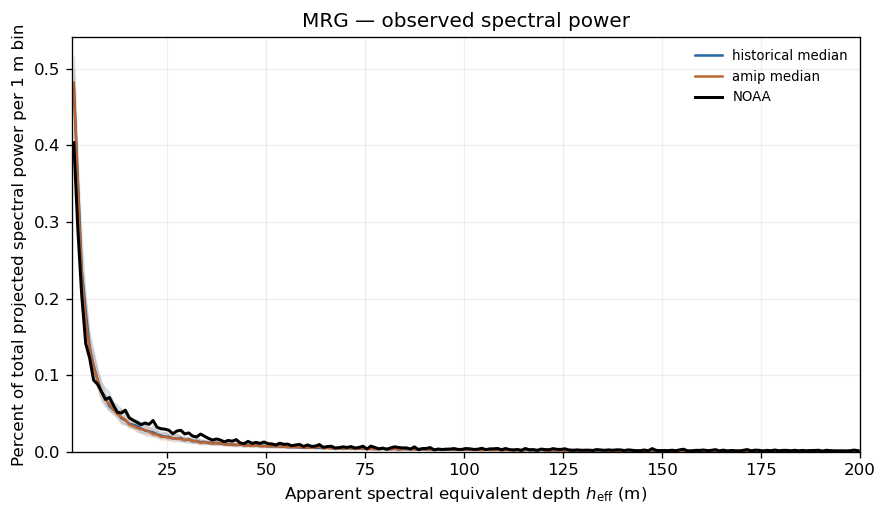

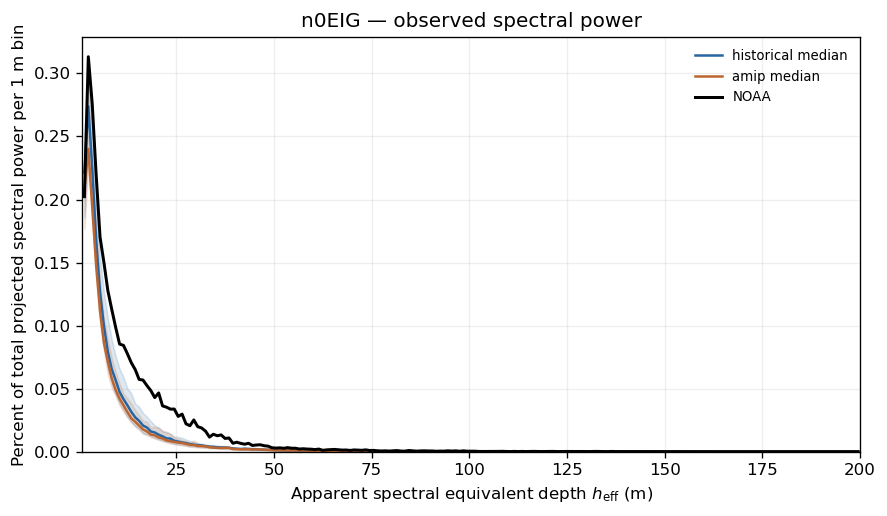

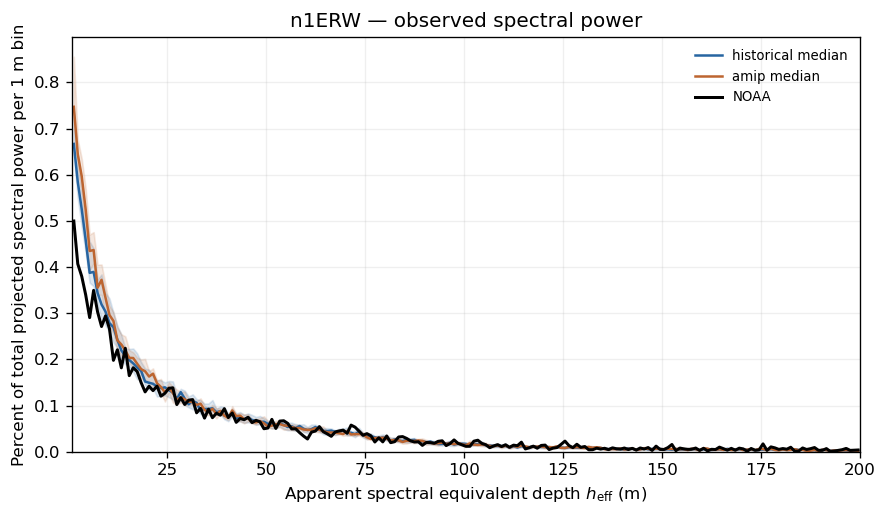

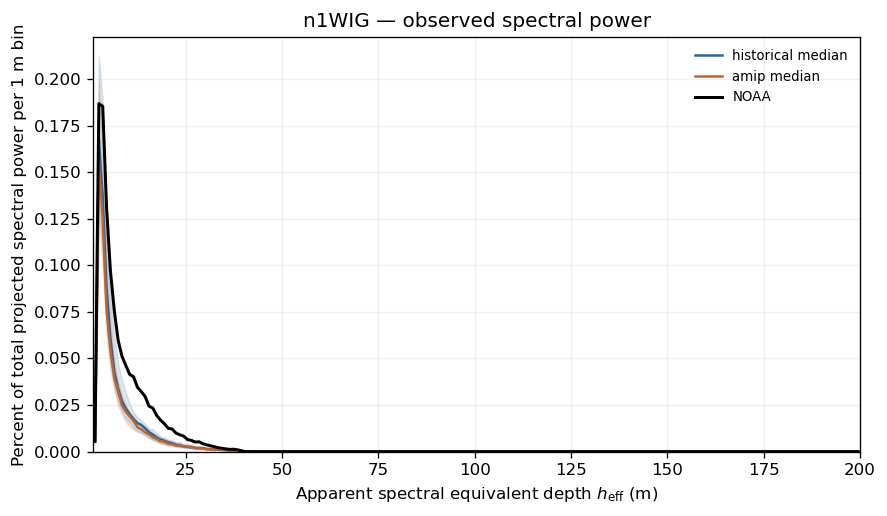

In [8]:
for wave in WAVES:
    fig, ax = plt.subplots(figsize=(7.5, 4.4), dpi=120)
    for experiment, color in (("historical", "#2765a1"), ("amip", "#bd6530")):
        rows = model_spectral.loc[(model_spectral.wave_type == wave)
                                  & (model_spectral.source == "observed")
                                  & (model_spectral.experiment == experiment)]
        fractions = 100 * rows[POWER_BINS].to_numpy() / rows.denominator_power.to_numpy()[:, None]
        low, median, high = np.quantile(fractions, [0.25, 0.5, 0.75], axis=0)
        ax.plot(centers, median, color=color, label=f"{experiment} median")
        ax.fill_between(centers, low, high, color=color, alpha=0.15)
    row = noaa_spectral.loc[(noaa_spectral.wave_type == wave)
                            & (noaa_spectral.source == "observed")].iloc[0]
    noaa_fraction = 100 * row[POWER_BINS].to_numpy(dtype=float) / row.denominator_power
    ax.plot(centers, noaa_fraction, color="black", linewidth=1.8, label="NOAA")
    ax.set(xlim=(1, 200), ylim=(0, None),
           xlabel=r"Apparent spectral equivalent depth $h_{\mathrm{eff}}$ (m)",
           ylabel="Percent of total projected spectral power per 1 m bin",
           title=f"{wave} — observed spectral power")
    ax.grid(alpha=0.2)
    ax.legend(frameon=False, fontsize=8)
    fig.tight_layout()
    display(fig)
    plt.close(fig)


## Interpretation and limits

For quality-screened 2σ events in 12–50 m, NOAA's event-footprint energy share
is 2.173% of total projected OLR energy for Kelvin, versus Historical/AMIP
model medians of 0.866/0.888%. For EIG it is 0.253%, versus 0.0148/0.0123%.
The models therefore assign smaller shares of total projected OLR energy to
these event footprints under the stronger threshold as well. These are
conditional, descriptive comparisons rather than significance tests.

All event curves and integrated event-energy values now describe the 2σ
population. Selection changes remain consequential: shortening active support
can increase in-sample R² while leaving fewer cycles to constrain propagation.
The threshold-comparison notebook separately compares the 1.5σ and 2σ recipes.

Count density, energy on event pixels and Fourier-cell power measure different
quantities. Event-footprint energy includes all filtered signal on those pixels;
it is not excess power above a background. The resting-background inversion
and assigned branch give apparent equivalent depths, not direct vertical-mode
measurements. Between-model spread and a single NOAA record do not establish
statistical significance or isolate forced differences from internal variability.

Daily sampling limits direction inference near the Nyquist frequency, especially
for WIG. These diagnostics do not recover subdaily propagation information.
